# Data Quality Clinic: EU Cities
## Obiettivo
Analizzare e validare il dataset delle capitali europee con controlli riproducibili e visualizzazioni chiare.

## Passaggi
1. Caricamento dati
2. Profiling base (shape, tipi, missing)
3. Controlli qualità (duplicati, regex, palindromi)
4. Visualizzazioni grafiche (distribuzioni, scatter)
5. Conclusioni e note operative

## Criteri di successo
- Dataset caricato senza errori
- Profiling mostra shape, tipi e missing coerenti
- Controlli qualità producono risultati leggibili
- Grafici renderizzati correttamente
- Notebook eseguibile end-to-end con "Run All"

In [28]:
import pandas as pd

# Percorso dataset
DATA_PATH = "data/raw/eu_cities.csv"

# Caricamento
df = pd.read_csv(DATA_PATH)

# Verifica minima
print("Caricato:", DATA_PATH)
print("Shape:", df.shape)
print("Colonne:", list(df.columns))


Caricato: data/raw/eu_cities.csv
Shape: (10, 5)
Colonne: ['country', 'capital', 'population', 'lat', 'lon']


In [29]:
print("Shape:", df.shape)
print("Dtypes:\n", df.dtypes)
print("Missing:\n", df.isna().sum())

Shape: (10, 5)
Dtypes:
 country        object
capital        object
population      int64
lat           float64
lon           float64
dtype: object
Missing:
 country       0
capital       0
population    0
lat           0
lon           0
dtype: int64


In [30]:
print("Dtypes:\n", df.dtypes)
print("\nMissing per colonna:\n", df.isna().sum())
print("\nPrime 5 righe:")
display(df.head())

Dtypes:
 country        object
capital        object
population      int64
lat           float64
lon           float64
dtype: object

Missing per colonna:
 country       0
capital       0
population    0
lat           0
lon           0
dtype: int64

Prime 5 righe:


,country,capital,population,lat,lon
0,Italy,Rome,2873000,41.9028,12.4964
1,France,Paris,2161000,48.8566,2.3522
2,Germany,Berlin,3769000,52.5200,13.4050
3,Spain,Madrid,3223000,40.4168,-3.7038
4,Portugal,Lisbon,504718,38.7223,-9.1393


In [31]:
# Duplicati per paese
dups_country = df.duplicated(subset=["country"]).sum()
print("Duplicati per country:", dups_country)

# Capitali che finiscono con vocale (a, e, i, o, u)
vocali = df[df["capital"].str.contains(r"[aeiouAEIOU]$", regex=True, na=False)]
print("\nCapitali che finiscono con vocale (prime 10):")
display(vocali.head(10))

# Palindromi di 5 lettere (senza regex)
s = df["capital"].astype(str).str.lower()
mask_pal5 = s.str.len().eq(5) & s.str[0].eq(s.str[4]) & s.str[1].eq(s.str[3])
palindromi = df[mask_pal5]

print("Capitali palindromiche di 5 lettere:")
display(palindromi)
print("Conteggio palindromi:", len(palindromi))

# Report sintetico
report = {
    "rows": len(df),
    "cols": len(df.columns),
    "missing_total": int(df.isna().sum().sum()),
    "duplicati_country": int(dups_country),
    "vocali_count": int(len(vocali)),
    "palindromi_count": int(len(palindromi)),
}
print("\nReport sintetico:", report)

Duplicati per country: 0

Capitali che finiscono con vocale (prime 10):


,country,capital,population,lat,lon
0,Italy,Rome,2873000,41.9028,12.4964


Capitali palindromiche di 5 lettere:


,country,capital,population,lat,lon


Conteggio palindromi: 0

Report sintetico: {'rows': 10, 'cols': 5, 'missing_total': 0, 'duplicati_country': 0, 'vocali_count': 1, 'palindromi_count': 0}


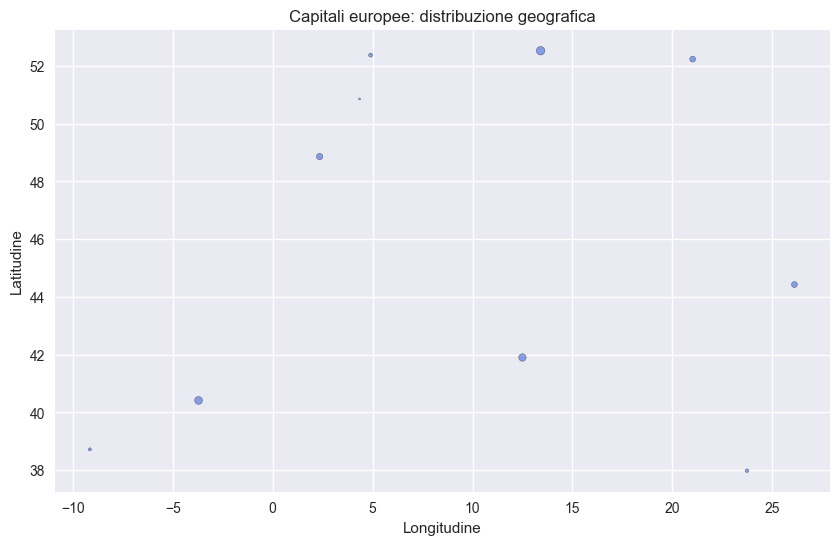

In [32]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
plt.scatter(df["lon"], df["lat"], s=df["population"]/100000, alpha=0.6, color="royalblue", edgecolor="black")

plt.title("Capitali europee: distribuzione geografica")
plt.xlabel("Longitudine")
plt.ylabel("Latitudine")

plt.show()

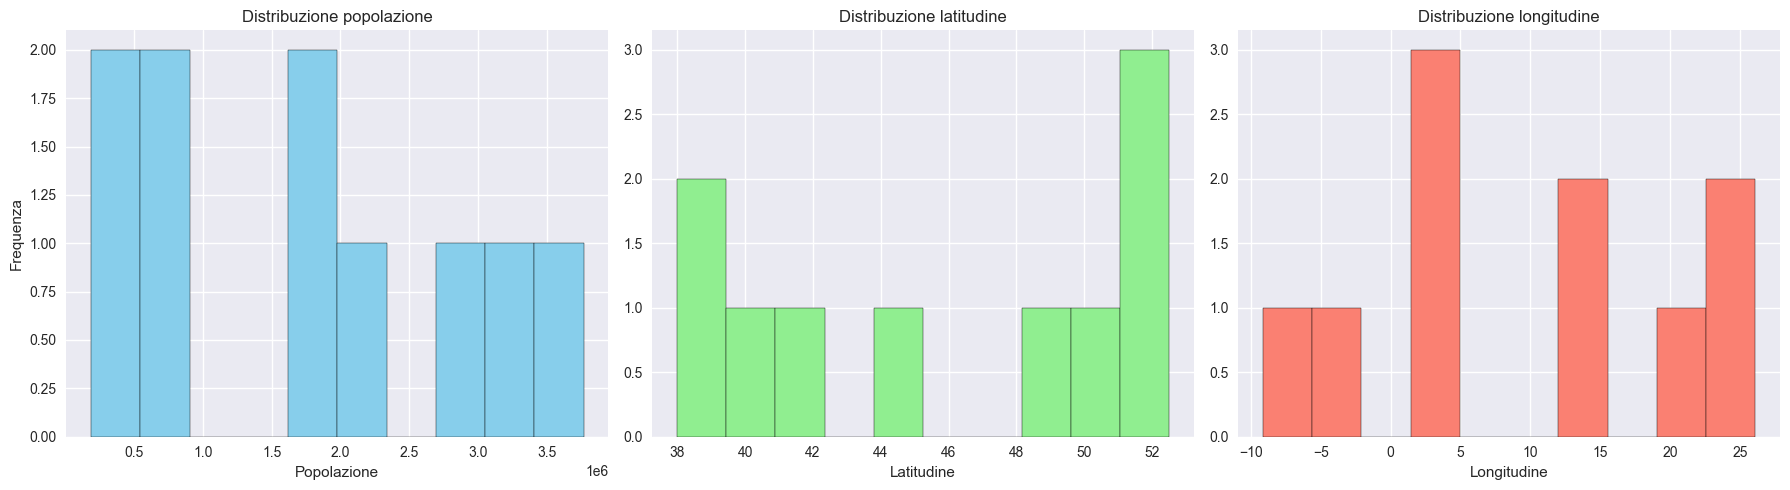

In [33]:
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8")

fig, axs = plt.subplots(1, 3, figsize=(18, 5))

# Istogramma popolazione
axs[0].hist(df["population"], bins=10, color="skyblue", edgecolor="black")
axs[0].set_title("Distribuzione popolazione")
axs[0].set_xlabel("Popolazione")
axs[0].set_ylabel("Frequenza")

# Istogramma latitudine
axs[1].hist(df["lat"], bins=10, color="lightgreen", edgecolor="black")
axs[1].set_title("Distribuzione latitudine")
axs[1].set_xlabel("Latitudine")

# Istogramma longitudine
axs[2].hist(df["lon"], bins=10, color="salmon", edgecolor="black")
axs[2].set_title("Distribuzione longitudine")
axs[2].set_xlabel("Longitudine")

plt.tight_layout()
plt.show()

In [ ]:
plt.figure(figsize=(10, 6))
sizes = (df["population"].fillna(0) / 100000).clip(lower=10, upper=400)  # scale e limiti
plt.scatter(df["lon"], df["lat"], s=sizes, alpha=0.6, color="royalblue", edgecolor="black")

plt.title("Capitali europee: distribuzione geografica")
plt.xlabel("Longitudine")
plt.ylabel("Latitudine")
plt.grid(True, alpha=0.2)
plt.show()

In [ ]:
import sys
import pandas as pd
import matplotlib as mpl

print("Python:", sys.version.split()[0], "| pandas:", pd.__version__, "| matplotlib:", mpl.__version__)

In [ ]:
## Conclusions
- Dataset loaded successfully with 10 rows and 5 columns.
- No missing values detected.
- No duplicate countries found.
- 1 capital ending with a vowel, 0 palindromic capitals of 5 letters.
- Visualizations show clear distributions of population, latitude, and longitude.
- Environment reproducibility confirmed (Python 3.14, pandas 2.3.3, matplotlib 3.10.7).
